In [25]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zara2099/multimodal-mental-health-assessment-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/zara2099/multimodal-mental-health-assessment-dataset


In [26]:
import kagglehub
import os
import glob
import pandas as pd

# Download latest dataset version
path = kagglehub.dataset_download(
    "zara2099/multimodal-mental-health-assessment-dataset"
)

print("Dataset downloaded to:", path)

# Find CSV files
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

print("\nAvailable CSV files:")
for file in csv_files:
    print(file)

# Load the mental health dataset
csv_path = next(
    f for f in csv_files
    if "mental_health_multimodal" in os.path.basename(f).lower()
)

df = pd.read_csv(csv_path)

# Inspect dataset
print("\nDataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isnull().sum())

Dataset downloaded to: /kaggle/input/datasets/zara2099/multimodal-mental-health-assessment-dataset

Available CSV files:
/kaggle/input/datasets/zara2099/multimodal-mental-health-assessment-dataset/mental_health_multimodal.csv

Dataset shape: (4000, 22)


,Depression_Score,Anxiety_Score,Stress_Score,Sleep_Quality,Social_Engagement,Daily_App_Usage_Min,Typing_Speed_WPM,Session_Frequency,Idle_Time_Min,Facial_Emotion_Variance,...,Head_Motion_Index,MFCC_Mean,MFCC_Variance,Pitch_Mean,Speech_Rate,Heart_Rate_BPM,HRV_Index,Skin_Temperature,GSR_Level,Mental_Health_Status
0,28,20,2,2,5,202,40,18,138,0.779,...,0.194,14.013,5.610,263.24,4.77,79,51.43,34.28,0.976,Mild_Stress
1,14,20,30,4,1,125,46,12,110,0.903,...,0.841,-31.755,6.633,168.32,3.56,116,41.22,32.60,3.294,Moderate_Stress
2,7,7,19,5,4,152,46,16,84,0.409,...,0.680,20.491,3.994,247.33,3.88,67,88.05,36.90,2.415,Healthy
3,20,22,18,4,3,41,69,4,167,0.266,...,0.451,20.541,25.291,195.57,2.54,78,82.37,36.06,0.736,Moderate_Stress
4,18,23,10,1,3,33,48,17,150,0.120,...,0.826,-14.997,24.731,285.88,4.61,113,59.69,34.27,4.589,Mild_Stress



Columns:
['Depression_Score', 'Anxiety_Score', 'Stress_Score', 'Sleep_Quality', 'Social_Engagement', 'Daily_App_Usage_Min', 'Typing_Speed_WPM', 'Session_Frequency', 'Idle_Time_Min', 'Facial_Emotion_Variance', 'Eye_Blink_Rate', 'Smile_Intensity', 'Head_Motion_Index', 'MFCC_Mean', 'MFCC_Variance', 'Pitch_Mean', 'Speech_Rate', 'Heart_Rate_BPM', 'HRV_Index', 'Skin_Temperature', 'GSR_Level', 'Mental_Health_Status']

Missing values:


Depression_Score           0
Anxiety_Score              0
Stress_Score               0
Sleep_Quality              0
Social_Engagement          0
Daily_App_Usage_Min        0
Typing_Speed_WPM           0
Session_Frequency          0
Idle_Time_Min              0
Facial_Emotion_Variance    0
Eye_Blink_Rate             0
Smile_Intensity            0
Head_Motion_Index          0
MFCC_Mean                  0
MFCC_Variance              0
Pitch_Mean                 0
Speech_Rate                0
Heart_Rate_BPM             0
HRV_Index                  0
Skin_Temperature           0
GSR_Level                  0
Mental_Health_Status       0
dtype: int64

In [27]:
# ============================================
# 6. CHECK EXPECTED VARIABLES
# ============================================

clinical_features = [
    "Depression_Score",
    "Anxiety_Score",
    "Stress_Score",
    "Sleep_Quality",
    "Social_Engagement",
    "Daily_App_Usage_Min",
    "Typing_Speed_WPM",
    "Session_Frequency",
    "Idle_Time_Min"
]

sensor_features = [
    "Facial_Emotion_Variance",
    "Eye_Blink_Rate",
    "Smile_Intensity",
    "Head_Motion_Index",
    "MFCC_Mean",
    "MFCC_Variance",
    "Pitch_Mean",
    "Speech_Rate",
    "Heart_Rate_BPM",
    "HRV_Index",
    "Skin_Temperature",
    "GSR_Level"
]

target_column = "Mental_Health_Status"

expected_columns = (
    clinical_features
    + sensor_features
    + [target_column]
)

missing_columns = [
    column for column in expected_columns
    if column not in df.columns
]

if missing_columns:
    print("Missing expected columns:")
    print(missing_columns)
else:
    print("All expected research variables are available.")

print("\nClinical features:", len(clinical_features))
print("Sensor features:", len(sensor_features))
print("Target variable:", target_column)

All expected research variables are available.

Clinical features: 9
Sensor features: 12
Target variable: Mental_Health_Status


In [28]:
# ============================================
# 7. DATA QUALITY CHECK
# ============================================

print("Missing values per column:")

missing_values = df.isnull().sum()

display(
    missing_values[missing_values > 0]
)

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nTarget distribution:")

if target_column in df.columns:
    display(df[target_column].value_counts(dropna=False))

Missing values per column:


Series([], dtype: int64)


Total missing values: 0

Duplicate records: 0

Target distribution:


Mental_Health_Status
Healthy            1629
Mild_Stress        1237
Moderate_Stress    1006
Severe_Stress       128
Name: count, dtype: int64

In [29]:
# ============================================
# 8. SAVE RAW DATA LOCALLY
# ============================================

project_root = Path.cwd()

data_folder = project_root / "data"
data_folder.mkdir(parents=True, exist_ok=True)

local_csv_path = data_folder / "mental_health_multimodal.csv"

df.to_csv(local_csv_path, index=False)

print("Dataset saved to:", local_csv_path)

Dataset saved to: /kaggle/working/data/mental_health_multimodal.csv


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import CCA
from sklearn.model_selection import KFold
from sklearn.utils import resample

from scipy.stats import pearsonr

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load your locally saved CSV
df = pd.read_csv("data/mental_health_multimodal.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (4000, 22)


,Depression_Score,Anxiety_Score,Stress_Score,Sleep_Quality,Social_Engagement,Daily_App_Usage_Min,Typing_Speed_WPM,Session_Frequency,Idle_Time_Min,Facial_Emotion_Variance,...,Head_Motion_Index,MFCC_Mean,MFCC_Variance,Pitch_Mean,Speech_Rate,Heart_Rate_BPM,HRV_Index,Skin_Temperature,GSR_Level,Mental_Health_Status
0,28,20,2,2,5,202,40,18,138,0.779,...,0.194,14.013,5.610,263.24,4.77,79,51.43,34.28,0.976,Mild_Stress
1,14,20,30,4,1,125,46,12,110,0.903,...,0.841,-31.755,6.633,168.32,3.56,116,41.22,32.60,3.294,Moderate_Stress
2,7,7,19,5,4,152,46,16,84,0.409,...,0.680,20.491,3.994,247.33,3.88,67,88.05,36.90,2.415,Healthy
3,20,22,18,4,3,41,69,4,167,0.266,...,0.451,20.541,25.291,195.57,2.54,78,82.37,36.06,0.736,Moderate_Stress
4,18,23,10,1,3,33,48,17,150,0.120,...,0.826,-14.997,24.731,285.88,4.61,113,59.69,34.27,4.589,Mild_Stress


In [31]:
# View A: Clinical and behavioural variables

clinical_features = [
    "Depression_Score",
    "Anxiety_Score",
    "Stress_Score",
    "Sleep_Quality",
    "Social_Engagement",
    "Daily_App_Usage_Min",
    "Typing_Speed_WPM",
    "Session_Frequency",
    "Idle_Time_Min"
]

# View B: Sensor-derived variables

sensor_features = [
    "Facial_Emotion_Variance",
    "Eye_Blink_Rate",
    "Smile_Intensity",
    "Head_Motion_Index",
    "MFCC_Mean",
    "MFCC_Variance",
    "Pitch_Mean",
    "Speech_Rate",
    "Heart_Rate_BPM",
    "HRV_Index",
    "Skin_Temperature",
    "GSR_Level"
]

# Extract matrices
X = df[clinical_features].copy()
Y = df[sensor_features].copy()

print("Clinical view:", X.shape)
print("Sensor view:", Y.shape)

assert X.shape[0] == Y.shape[0]
assert X.notna().all().all()
assert Y.notna().all().all()

Clinical view: (4000, 9)
Sensor view: (4000, 12)


In [32]:
# Standardise both feature matrices

scaler_X = StandardScaler()
scaler_Y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)
Y_scaled = scaler_Y.fit_transform(Y)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=clinical_features
)

Y_scaled = pd.DataFrame(
    Y_scaled,
    columns=sensor_features
)

print("Standardisation completed.")

display(X_scaled.describe().round(2))

Standardisation completed.


,Depression_Score,Anxiety_Score,Stress_Score,Sleep_Quality,Social_Engagement,Daily_App_Usage_Min,Typing_Speed_WPM,Session_Frequency,Idle_Time_Min
count,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00
mean,-0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.71,-1.69,-1.70,-1.41,-1.38,-1.68,-1.67,-1.69,-1.72
25%,-0.82,-0.86,-0.82,-0.71,-0.68,-0.89,-0.88,-0.95,-0.87
50%,0.02,-0.03,-0.02,-0.01,0.03,-0.02,-0.03,-0.02,-0.02
75%,0.86,0.80,0.86,0.70,0.74,0.88,0.86,0.90,0.89
max,1.66,1.64,1.74,1.40,1.44,1.74,1.76,1.64,1.72


In [33]:
# Fit CCA

n_components = 2

cca = CCA(
    n_components=n_components,
    max_iter=2000,
    scale=False,
    tol=1e-7
)

X_canonical, Y_canonical = cca.fit_transform(
    X_scaled,
    Y_scaled
)

print("CCA model fitted successfully.")

print("Clinical canonical scores:", X_canonical.shape)
print("Sensor canonical scores:", Y_canonical.shape)

CCA model fitted successfully.
Clinical canonical scores: (4000, 2)
Sensor canonical scores: (4000, 2)


In [34]:
# Calculate correlation between corresponding canonical variates

canonical_correlations = []

for i in range(n_components):

    correlation, p_value = pearsonr(
        X_canonical[:, i],
        Y_canonical[:, i]
    )

    canonical_correlations.append({
        "Canonical Dimension": i + 1,
        "Correlation": correlation,
        "P-value": p_value
    })

cca_results = pd.DataFrame(canonical_correlations)

display(cca_results.round(5))

,Canonical Dimension,Correlation,P-value
0,1,0.07967,0.0
1,2,0.07422,0.0


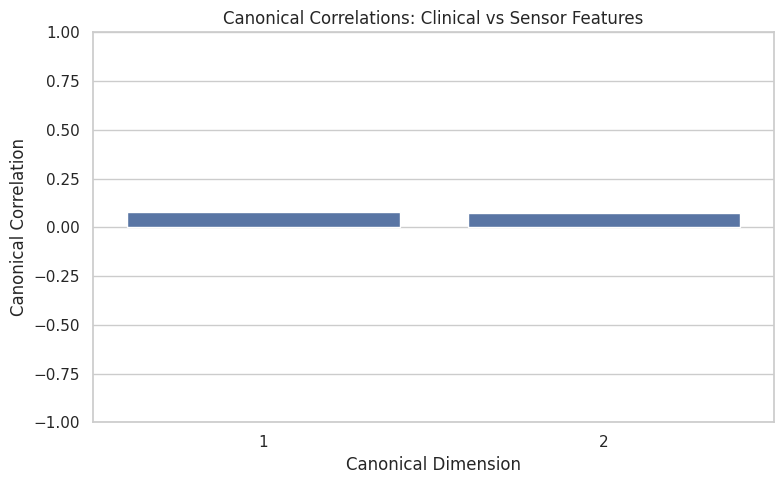

In [35]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=cca_results,
    x="Canonical Dimension",
    y="Correlation"
)

plt.title("Canonical Correlations: Clinical vs Sensor Features")
plt.ylabel("Canonical Correlation")
plt.xlabel("Canonical Dimension")
plt.ylim(-1, 1)

plt.tight_layout()




plt.show()

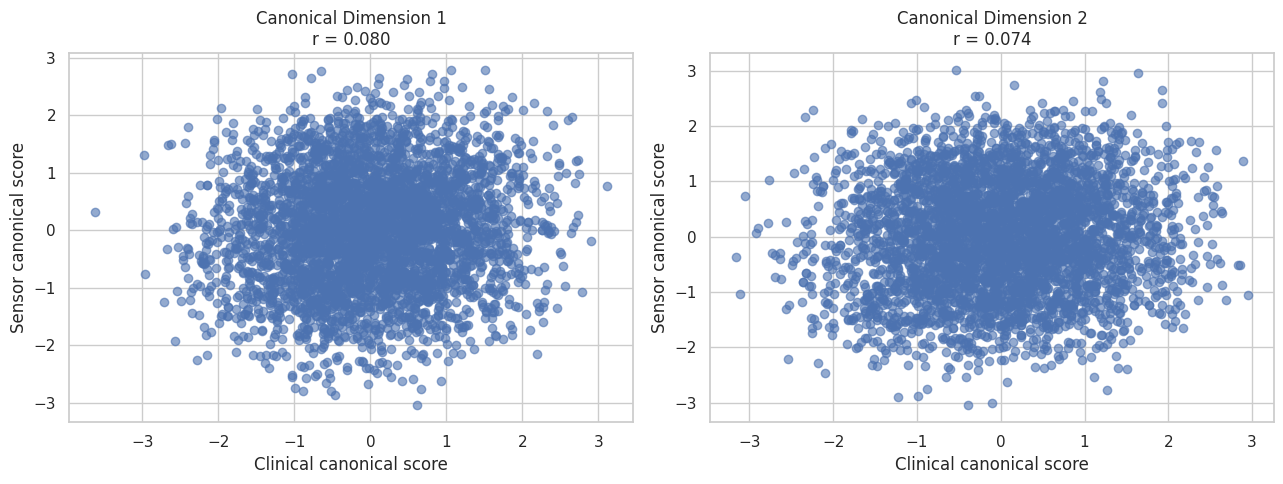

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, ax in enumerate(axes):

    ax.scatter(
        X_canonical[:, i],
        Y_canonical[:, i],
        alpha=0.6
    )

    correlation = np.corrcoef(
        X_canonical[:, i],
        Y_canonical[:, i]
    )[0, 1]

    ax.set_title(
        f"Canonical Dimension {i+1}\nr = {correlation:.3f}"
    )

    ax.set_xlabel("Clinical canonical score")
    ax.set_ylabel("Sensor canonical score")

plt.tight_layout()


plt.show()

In [37]:
# Calculate feature-to-canonical-variate correlations

clinical_loadings = pd.DataFrame(
    {
        f"Dimension_{i+1}": [
            np.corrcoef(
                X_scaled[col],
                X_canonical[:, i]
            )[0, 1]
            for col in clinical_features
        ]
        for i in range(n_components)
    },
    index=clinical_features
)

sensor_loadings = pd.DataFrame(
    {
        f"Dimension_{i+1}": [
            np.corrcoef(
                Y_scaled[col],
                Y_canonical[:, i]
            )[0, 1]
            for col in sensor_features
        ]
        for i in range(n_components)
    },
    index=sensor_features
)

print("Clinical feature loadings:")
display(clinical_loadings.round(3))

print("Sensor feature loadings:")
display(sensor_loadings.round(3))

Clinical feature loadings:


,Dimension_1,Dimension_2
Depression_Score,-0.322,0.389
Anxiety_Score,0.104,-0.443
Stress_Score,-0.095,0.624
Sleep_Quality,-0.183,0.136
Social_Engagement,0.425,-0.017
Daily_App_Usage_Min,0.494,0.008
Typing_Speed_WPM,-0.132,0.129
Session_Frequency,0.163,0.222
Idle_Time_Min,0.600,0.404


Sensor feature loadings:


,Dimension_1,Dimension_2
Facial_Emotion_Variance,0.017,-0.275
Eye_Blink_Rate,-0.115,0.235
Smile_Intensity,0.562,0.214
Head_Motion_Index,0.099,-0.806
MFCC_Mean,0.383,-0.045
MFCC_Variance,0.044,-0.211
Pitch_Mean,-0.585,-0.052
Speech_Rate,0.076,0.079
Heart_Rate_BPM,-0.066,-0.153
HRV_Index,0.089,-0.130


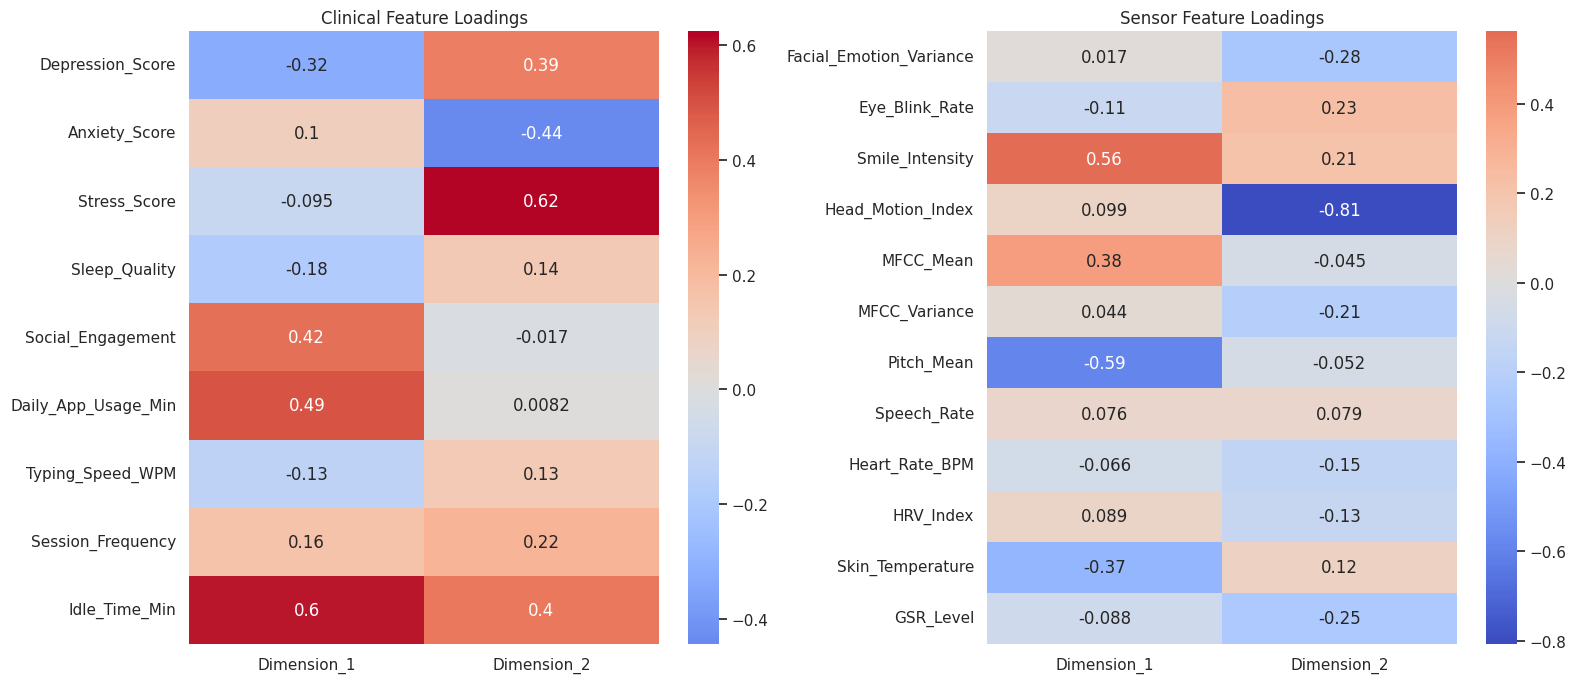

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(
    clinical_loadings,
    annot=True,
    cmap="coolwarm",
    center=0,
    ax=axes[0]
)

axes[0].set_title("Clinical Feature Loadings")

sns.heatmap(
    sensor_loadings,
    annot=True,
    cmap="coolwarm",
    center=0,
    ax=axes[1]
)

axes[1].set_title("Sensor Feature Loadings")

plt.tight_layout()


plt.show()

In [42]:
import sys
import importlib.util

print("Python version:", sys.version)

packages = [
    "numpy",
    "pandas",
    "sklearn",
    "matplotlib",
    "seaborn",
    "ripser",
    "persim",
    "gudhi"
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(package, ":", installed)

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
numpy : True
pandas : True
sklearn : True
matplotlib : True
seaborn : True
ripser : False
persim : False
gudhi : False


In [43]:
%pip install ripser persim

ERROR: Could not find a version that satisfies the requirement ripser (from versions: none)
ERROR: No matching distribution found for ripser
Note: you may need to restart the kernel to use updated packages.
